# Electiva III · Ciclo de datos con la API de la NVD (CVE)

Este notebook cubre la parte de **Electiva III** del proyecto. Recorre el ciclo completo de manejo de datos con los CVE publicados en los **últimos 7 días**: consultar la API → obtener la data → construir el dataset → limpiar → exportar a **CSV** → análisis descriptivo.

El **CSV que se exporta es el archivo de entrada del software de Estadística Inferencial**. Se separó a propósito: aquí se hace la parte de datos y allá la de probabilidad (el software también puede consultar la API por su cuenta, pero queremos probar los dos pasos por separado). La ventana de 7 días depende del día en que se ejecute, así que el CSV es una muestra de ese día.

| Sección | Qué se hace | Resultado |
|---|---|---|
| 1. Consulta a la API | Parámetros, encabezados, paginación y descarga día por día | `vulnerabilidades` (lista de JSON) |
| 2. Obtención de la data cruda | Revisar la forma del JSON y guardarlo tal como llegó | `nvd_crudo.json` |
| 3. Construcción del dataset | Una fila por CVE, una sola puntuación CVSS por CVE | `df_bruto` |
| 4. Limpieza | Inspección, rechazados, duplicados, tipos, strings, nulos y validaciones | `df` |
| 5. Dataset final y exportación | Columnas definitivas, diccionario de datos y CSV | `cve_nvd_ultimos_7_dias.csv` |
| 6. Análisis descriptivo | Resúmenes, frecuencias, gráficos y hallazgos | tablas y gráficos |

### Relación con el proceso de web scraping
La NVD ofrece una **API oficial**, y las lecturas del curso indican que, si el sitio tiene API, se usa esa en lugar de scrapear el HTML. El ciclo es el mismo; cambia la herramienta:

| Paso del scraping | Aquí con la API |
|---|---|
| 1. Inspeccionar | Leer la documentación de la CVE API 2.0: base `…/rest/json/cves/2.0` y parámetros `pubStartDate`, `pubEndDate`, `resultsPerPage`, `startIndex` |
| 2. Descargar | `requests.get(url, params=..., headers=...)` |
| 3. Parsear | `respuesta.json()`: ya llega estructurado, no hay HTML que convertir con BeautifulSoup |
| 4. Navegar | Recorrer `vulnerabilities → cve → metrics → cvssData` (lo equivalente a `find`, `find_all` y `.parent`) |
| 5. Extraer | Tomar los campos útiles y armar una fila por CVE |

Los límites legales y éticos también aplican: **no saturar** (pausas entre peticiones), **la clave va en los Secretos de Colab y nunca en el código**, y los datos son públicos y sin información personal.

### Cuidados con los datos
- **Hay tres versiones de CVSS a la vez** (v3.0, v3.1 y v4.0) y un mismo CVE puede traer más de una. Se elige una sola por CVE, con prioridad v3.1 → v3.0 → v4.0, para no mezclar escalas.
- **No todos los CVE tienen puntuación**: varios están en *Awaiting Analysis*, *Deferred* o *Received*. Se filtran en la limpieza y se reporta cuántos se descartan.
- **v4.0 no trae `exploitabilityScore` ni `impactScore`**; esas dos columnas solo valen para v3.x.
- **Los datos cambian con el día de ejecución**: la ventana se mueve y la NVD sigue actualizando CVE ya publicados. Para congelar una muestra se guarda el CSV.
- La API devuelve como máximo 2000 resultados por página, por eso se pagina. El límite de 120 días por rango y los límites de solicitudes los tomamos de fuentes de la comunidad y **no están verificados** en la página oficial: https://nvd.nist.gov/developers/vulnerabilities.

## 1. Consulta a la API

Se descargan los CVE **publicados** en los últimos `DIAS_ATRAS` días, **un día por consulta** (con paginación si un día pasa de 2000). Las fechas de la NVD están en **UTC**, así que la ventana se calcula en UTC.

Por defecto se toman **7 días completos que terminan ayer** (`INCLUIR_HOY = False`), porque el día de hoy suele estar incompleto. Con `INCLUIR_HOY = True` la ventana termina hoy.

Sin API key hay un límite bajo de peticiones, por eso se espera unos segundos entre llamadas. La clave se lee de los **Secretos de Colab** (`NVD_API_KEY`) y va en el encabezado `apiKey`; si no existe, el notebook sigue sin ella.

In [4]:
import json
import re
import time

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from google.colab import userdata
from IPython.display import display

# --- Parámetros de la consulta ---
DIAS_ATRAS = 7          # cuántos días recientes se descargan
INCLUIR_HOY = False     # False: 7 días completos que terminan ayer | True: la ventana termina hoy (hoy puede estar incompleto)
POR_PAGINA = 2000       # máximo permitido por la API
PAUSA = 6               # segundos entre peticiones (sin API key)

try:
    API_KEY = userdata.get("NVD_API_KEY")
except Exception:
    API_KEY = None      # sin secreto o sin acceso: se sigue sin API key

url = "https://services.nvd.nist.gov/rest/json/cves/2.0"
head = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}
if API_KEY:
    head["apiKey"] = API_KEY
    PAUSA = 1
    print("se cargó la API_KEY")
else:
    print("sin API_KEY: se esperarán", PAUSA, "s entre peticiones")

se cargó la API_KEY


In [5]:
def pedir_pagina(dia, inicio):
    # Pide una página de los CVE publicados en un día; si hay error, reintenta hasta 3 veces.
    params = {
        "pubStartDate": dia.strftime("%Y-%m-%dT00:00:00.000"),
        "pubEndDate": dia.strftime("%Y-%m-%dT23:59:59.999"),
        "resultsPerPage": POR_PAGINA,
        "startIndex": inicio,
    }
    for intento in range(3):
        try:
            r = requests.get(url, params=params, headers=head, timeout=60)
        except requests.RequestException as error:
            print(f"Error de conexión el {dia.date()} ({error}). Reintento {intento + 1}/3...")
        else:
            if r.status_code == 200:
                return r.json()
            print(f"Código {r.status_code} el {dia.date()} (startIndex={inicio}). Reintento {intento + 1}/3...")
        time.sleep(30)
    raise RuntimeError(f"No se pudo obtener la página del {dia.date()} con startIndex={inicio}")

In [6]:
# --- Ventana de días (la NVD usa UTC) ---
hoy = pd.Timestamp.now(tz="UTC").normalize().tz_localize(None)
ultimo_dia = hoy if INCLUIR_HOY else hoy - pd.Timedelta(days=1)
dias = pd.date_range(end=ultimo_dia, periods=DIAS_ATRAS)
print("Días a descargar:", [d.strftime("%d-%b (%a)") for d in dias])

# --- Descarga día por día (cada día completo, con paginación si pasa de 2000) ---
vulnerabilidades = []
conteo_api = {}          # CVE que la API dice tener por día (para cuadrar después)
t0 = time.time()

for dia in dias:
    inicio = 0
    total = None
    while total is None or inicio < total:
        pagina = pedir_pagina(dia, inicio)
        total = pagina["totalResults"]
        vulnerabilidades.extend(pagina["vulnerabilities"])
        inicio += POR_PAGINA
        time.sleep(PAUSA)
    conteo_api[dia.date()] = total
    print(f"{dia.date()}: {total} CVE   (acumulado {len(vulnerabilidades)}, {time.time() - t0:.0f} s)")

print("\nListo. Registros descargados:", len(vulnerabilidades))

Días a descargar: ['12-Nov (Thu)', '13-Nov (Fri)', '14-Nov (Sat)', '15-Nov (Sun)', '16-Nov (Mon)', '17-Nov (Tue)', '18-Nov (Wed)']
2026-11-12: 366 CVE   (acumulado 366, 1 s)
2026-11-13: 794 CVE   (acumulado 1160, 3 s)
2026-11-14: 64 CVE   (acumulado 1224, 4 s)
2026-11-15: 112 CVE   (acumulado 1336, 6 s)
2026-11-16: 357 CVE   (acumulado 1693, 29 s)
2026-11-17: 1230 CVE   (acumulado 2923, 30 s)
2026-11-18: 722 CVE   (acumulado 3645, 32 s)

Listo. Registros descargados: 3645


## 2. Obtención de la data cruda

Antes de transformar nada conviene **mirar cómo llegó** el JSON y **guardarlo tal cual**: si después se cambia una regla de limpieza no hace falta volver a consultar la API (y la ventana de 7 días ya se habría movido).

El JSON es **semiestructurado** (como los de `firstnb`): la lista `vulnerabilidades` trae un elemento por CVE y dentro de `cve` hay objetos y listas anidadas. Al aplanarlo con `pd.json_normalize` se ve el problema: las métricas quedan como listas dentro de celdas y no sirven todavía para analizar.

In [7]:
ARCHIVO_CRUDO = "nvd_crudo.json"

# Forma de un registro: vulnerabilities -> cve -> (id, published, metrics, weaknesses, references...)
print("Registros descargados:", len(vulnerabilidades))
print("Claves de un registro:", list(vulnerabilidades[0].keys()))
print("Claves dentro de 'cve':", list(vulnerabilidades[0]["cve"].keys()))

# ¿Qué versiones de CVSS aparecen? (cuántos CVE traen cada bloque de métricas)
from collections import Counter
bloques_cvss = Counter(clave for v in vulnerabilidades for clave in v["cve"].get("metrics", {}))
print("\nCVE que traen cada bloque de métricas:", dict(bloques_cvss))
print("CVE sin ninguna métrica:", sum(1 for v in vulnerabilidades if not v["cve"].get("metrics")))

# Se guarda la respuesta cruda sin modificar
with open(ARCHIVO_CRUDO, "w", encoding="utf-8") as f:
    json.dump(vulnerabilidades, f)
print(f"\nGuardado: {ARCHIVO_CRUDO}")

# Aplanado directo (solo para ver el problema: las métricas quedan como listas en las celdas)
crudo_plano = pd.json_normalize(vulnerabilidades[:200])
print("Aplanado directo de 200 registros:", crudo_plano.shape)
crudo_plano.iloc[:3, :8]

Registros descargados: 3645
Claves de un registro: ['cve']
Claves dentro de 'cve': ['id', 'sourceIdentifier', 'published', 'lastModified', 'vulnStatus', 'cveTags', 'descriptions', 'affected', 'metrics', 'weaknesses', 'references']

CVE que traen cada bloque de métricas: {'cvssMetricV40': 1531, 'cvssMetricV31': 3011, 'cvssMetricV2': 67, 'ssvcV203': 2994, 'cvssMetricV30': 55}
CVE sin ninguna métrica: 84

Guardado: nvd_crudo.json
Aplanado directo de 200 registros: (200, 20)


,cve.id,cve.sourceIdentifier,cve.published,cve.lastModified,cve.vulnStatus,cve.cveTags,cve.descriptions,cve.affected
0,CVE-2026-126759,cna@vuldb.com,2026-11-12T00:17:14.527,2026-11-12T18:17:26.923,Deferred,[],"[{'lang': 'en', 'value': 'A flaw has been foun...","[{'source': 'cna@vuldb.com', 'affectedData': [..."
1,CVE-2026-125785,audit@patchstack.com,2026-11-12T01:17:11.003,2026-11-13T17:17:21.577,Deferred,[],"[{'lang': 'en', 'value': 'Improper Neutralizat...","[{'source': 'audit@patchstack.com', 'affectedD..."
2,CVE-2026-125786,audit@patchstack.com,2026-11-12T01:17:11.150,2026-11-12T17:17:32.053,Deferred,[],"[{'lang': 'en', 'value': 'Improper Neutralizat...","[{'source': 'audit@patchstack.com', 'affectedD..."


## 3. Construcción del dataset (un CVE por fila)

Un mismo CVE puede traer varias métricas (v3.0, v3.1, v4.0) y de distintas fuentes. Para no mezclar escalas se elige **una sola puntuación por CVE** siguiendo el orden de `ORDEN_VERSIONES`, y dentro de cada versión se prefiere la fuente `Primary`. Es el paso de **navegar y extraer**: se recorre el JSON y se saca de cada CVE solo lo útil.

En esta sección **no se limpia nada todavía**: `df_bruto` queda tal como salió del JSON (con los CVE rechazados, los sin puntuación y los tipos sin convertir). La limpieza va en la sección 4.

La variable `critico` es de Bernoulli: **1** si la severidad es CRITICAL, **0** si no, y vacía si el CVE no tiene puntuación. Es la que usa el software de Estadística.

In [8]:
# Orden de preferencia de la versión de CVSS (se puede cambiar)
ORDEN_VERSIONES = ["cvssMetricV31", "cvssMetricV30", "cvssMetricV40"]

def elegir_metrica(cve):
    # Devuelve (versión, métrica) de la primera versión disponible, o (None, {}).
    # La métrica trae 'cvssData' y, en v3.x, también exploitabilityScore e impactScore.
    metricas = cve.get("metrics", {})
    for clave in ORDEN_VERSIONES:
        registros = metricas.get(clave)
        if registros:
            primarios = [m for m in registros if m.get("type") == "Primary"]
            return clave, (primarios[0] if primarios else registros[0])
    return None, {}

def sacar(patron, vector):
    # Extrae un valor del vector CVSS (p. ej. AV:N -> 'N').
    if not vector:
        return None
    m = re.search(patron, vector)
    return m.group(1) if m else None

filas = []
for v in vulnerabilidades:
    cve = v["cve"]
    version, metrica = elegir_metrica(cve)
    cvss = metrica.get("cvssData", {})
    vector = cvss.get("vectorString")
    puntuacion = cvss.get("baseScore")
    severidad = cvss.get("baseSeverity")
    debilidades = cve.get("weaknesses", [])
    cwe = debilidades[0]["description"][0]["value"] if debilidades and debilidades[0].get("description") else None
    ui = sacar(r"/UI:([NRPA])", vector)   # v3: N/R; v4: N/P/A (P y A se tratan como "requiere interacción")
    filas.append({
        "id": cve["id"],
        "fecha": cve["published"],
        "estado": cve.get("vulnStatus"),
        "version": version,
        "baseScore": puntuacion,
        "severidad": severidad,
        # Variable de Bernoulli: 1 = crítico, 0 = no crítico, vacío = sin puntuación
        "critico": None if puntuacion is None else int(severidad == "CRITICAL"),
        "vector_ataque": sacar(r"/AV:([NALP])", vector),       # N = red, A = adyacente, L = local, P = físico
        "complejidad_ataque": sacar(r"/AC:([LH])", vector),    # L = baja, H = alta
        "privilegios": sacar(r"/PR:([NLH])", vector),          # N = ninguno, L = bajo, H = alto
        "interaccion_usuario": None if ui is None else ("N" if ui == "N" else "R"),   # N = ninguna, R = requiere
        "impacto_conf": sacar(r"/V?C:([NLH])", vector),        # confidencialidad (en v4.0 se toma VC)
        "impacto_integ": sacar(r"/V?I:([NLH])", vector),       # integridad (en v4.0 se toma VI)
        "impacto_disp": sacar(r"/V?A:([NLH])", vector),        # disponibilidad (en v4.0 se toma VA)
        "exploitabilityScore": metrica.get("exploitabilityScore"),   # solo v3.x
        "impactScore": metrica.get("impactScore"),                   # solo v3.x
        "cwe": cwe,                                            # primera debilidad asociada
        "fuente": cve.get("sourceIdentifier"),                 # quién reportó el CVE
        "n_referencias": len(cve.get("references", [])),
        "kev": "cisaExploitAdd" in cve,                        # True si está en el catálogo CISA de explotadas
    })

df_bruto = pd.DataFrame(filas)
print("df_bruto:", df_bruto.shape)
df_bruto.head()

df_bruto: (3645, 20)


,id,fecha,estado,version,baseScore,severidad,critico,vector_ataque,complejidad_ataque,privilegios,interaccion_usuario,impacto_conf,impacto_integ,impacto_disp,exploitabilityScore,impactScore,cwe,fuente,n_referencias,kev
0,CVE-2026-126759,2026-11-12T00:17:14.527,Deferred,cvssMetricV31,5.3,MEDIUM,0.0,N,L,N,N,L,N,N,3.9,1.4,CWE-287,cna@vuldb.com,4,False
1,CVE-2026-125785,2026-11-12T01:17:11.003,Deferred,cvssMetricV31,6.5,MEDIUM,0.0,N,L,L,R,L,L,L,2.3,3.7,CWE-79,audit@patchstack.com,1,False
2,CVE-2026-125786,2026-11-12T01:17:11.150,Deferred,cvssMetricV31,5.3,MEDIUM,0.0,N,L,N,N,L,N,N,3.9,1.4,CWE-80,audit@patchstack.com,1,False
3,CVE-2026-125787,2026-11-12T01:17:11.297,Deferred,cvssMetricV31,5.4,MEDIUM,0.0,N,L,L,N,L,L,N,2.8,2.5,CWE-862,audit@patchstack.com,1,False
4,CVE-2026-126673,2026-11-12T01:17:11.457,Deferred,cvssMetricV31,9.8,CRITICAL,1.0,N,L,N,N,H,H,H,3.9,5.9,CWE-94,9b29abf9-4ab0-4765-b253-1875cd9b441e,2,False


## 4. Limpieza

Se sigue el orden del notebook de *transformación y limpieza de datos*: inspección, filas que sobran, duplicados, tipos de datos, strings y nulos. Se trabaja sobre una copia (`df`) para conservar `df_bruto` intacto.

Las columnas ya se seleccionaron en la sección 3, así que aquí no hay columnas que eliminar: lo que se depura son **filas**.

### 4.1 Inspección

In [9]:
df = df_bruto.copy()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3645 entries, 0 to 3644
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   3645 non-null   object 
 1   fecha                3645 non-null   object 
 2   estado               3645 non-null   object 
 3   version              3559 non-null   object 
 4   baseScore            3559 non-null   float64
 5   severidad            3559 non-null   object 
 6   critico              3559 non-null   float64
 7   vector_ataque        3559 non-null   object 
 8   complejidad_ataque   3559 non-null   object 
 9   privilegios          3559 non-null   object 
 10  interaccion_usuario  3559 non-null   object 
 11  impacto_conf         3559 non-null   object 
 12  impacto_integ        3559 non-null   object 
 13  impacto_disp         3559 non-null   object 
 14  exploitabilityScore  3066 non-null   float64
 15  impactScore          3066 non-null   f

In [10]:
# Inventario de columnas: tipo, nulos y valores distintos
inventario = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "% nulos": (df.isna().mean() * 100).round(1),
    "distintos": df.nunique(),
})
inventario

,tipo,nulos,% nulos,distintos
id,object,0,0.0,3645
fecha,object,0,0.0,3645
estado,object,0,0.0,7
version,object,86,2.4,3
baseScore,float64,86,2.4,83
severidad,object,86,2.4,4
critico,float64,86,2.4,2
vector_ataque,object,86,2.4,4
complejidad_ataque,object,86,2.4,2
privilegios,object,86,2.4,3


### 4.2 Filas que no son vulnerabilidades (`Rejected`)
Los CVE con estado `Rejected` fueron retirados por la propia NVD: no son vulnerabilidades reales y se excluyen.

In [11]:
print(df["estado"].value_counts())

rechazados = int((df["estado"] == "Rejected").sum())
df = df[df["estado"] != "Rejected"].copy()
print("\nCVE rechazados (Rejected) excluidos:", rechazados)
print("CVE restantes:", len(df))

estado
Received               1549
Deferred               1055
Awaiting Analysis       628
Undergoing Analysis     209
Analyzed                178
Rejected                 22
Modified                  4
Name: count, dtype: int64

CVE rechazados (Rejected) excluidos: 22
CVE restantes: 3623


### 4.3 Duplicados
Cada CVE debe aparecer una sola vez. Se busca por `id` (duplicado parcial) y se conserva el primero.

In [12]:
duplicados = int(df.duplicated(subset=["id"]).sum())
print("CVE duplicados (mismo id):", duplicados)

df = df.drop_duplicates(subset=["id"], keep="first").reset_index(drop=True)
print("CVE después de quitar duplicados:", len(df))

CVE duplicados (mismo id): 0
CVE después de quitar duplicados: 3623


### 4.4 Tipos de datos
Las puntuaciones deben ser numéricas (`float`), `critico` un entero que admita vacíos (`Int8`), `fecha` una fecha, y `kev` un booleano.

In [13]:
for col in ["baseScore", "exploitabilityScore", "impactScore"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["critico"] = df["critico"].astype("Int8")
df["fecha"] = pd.to_datetime(df["fecha"]).dt.date     # día de publicación (UTC)
df["n_referencias"] = df["n_referencias"].astype(int)
df["kev"] = df["kev"].astype(bool)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3623 entries, 0 to 3622
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   3623 non-null   object 
 1   fecha                3623 non-null   object 
 2   estado               3623 non-null   object 
 3   version              3559 non-null   object 
 4   baseScore            3559 non-null   float64
 5   severidad            3559 non-null   object 
 6   critico              3559 non-null   Int8   
 7   vector_ataque        3559 non-null   object 
 8   complejidad_ataque   3559 non-null   object 
 9   privilegios          3559 non-null   object 
 10  interaccion_usuario  3559 non-null   object 
 11  impacto_conf         3559 non-null   object 
 12  impacto_integ        3559 non-null   object 
 13  impacto_disp         3559 non-null   object 
 14  exploitabilityScore  3066 non-null   float64
 15  impactScore          3066 non-null   f

### 4.5 Limpieza de strings
Se quitan espacios sobrantes y se unifican las mayúsculas en las columnas de texto, para que `"N"` y `" n "` no cuenten como valores distintos.

In [14]:
columnas_codigo = ["id", "estado", "severidad", "vector_ataque", "complejidad_ataque", "privilegios",
                   "interaccion_usuario", "impacto_conf", "impacto_integ", "impacto_disp", "cwe"]

for col in columnas_codigo:
    df[col] = df[col].str.strip()
for col in ["id", "severidad", "vector_ataque", "complejidad_ataque", "privilegios",
            "interaccion_usuario", "impacto_conf", "impacto_integ", "impacto_disp"]:
    df[col] = df[col].str.upper()
df["fuente"] = df["fuente"].str.strip().str.lower()     # correos de quien reportó el CVE

# Los valores distintos de cada columna categórica deben ser pocos y esperados
for col in ["severidad", "vector_ataque", "complejidad_ataque", "privilegios", "interaccion_usuario"]:
    print(col, "->", sorted(df[col].dropna().unique()))

severidad -> ['CRITICAL', 'HIGH', 'LOW', 'MEDIUM']
vector_ataque -> ['A', 'L', 'N', 'P']
complejidad_ataque -> ['H', 'L']
privilegios -> ['H', 'L', 'N']
interaccion_usuario -> ['N', 'R']


### 4.6 Datos nulos o faltantes
No todo nulo se elimina. Aquí hay tres casos distintos:

- **Sin puntuación** (`baseScore` vacío, y con él `severidad`, `critico` y el vector): son CVE sin analizar. Sin puntuación no hay evento «crítico», así que se **descartan** del dataset y se cuenta cuántos fueron. Con `SOLO_CON_PUNTUACION = False` se conservan.
- **`exploitabilityScore` e `impactScore` vacíos**: es lo esperado en v4.0, que no los trae. **No se tocan**.
- **`cwe` vacío**: CVE sin debilidad asignada. **No se toca**.

In [15]:
SOLO_CON_PUNTUACION = True    # True: se descartan los CVE sin puntuación | False: se conservan (quedan con celdas vacías)

nulos = pd.DataFrame({"nulos": df.isna().sum(), "% nulos": (df.isna().mean() * 100).round(1)})
display(nulos[nulos["nulos"] > 0])

sin_puntuacion = int(df["baseScore"].isna().sum())
print("\nCVE sin puntuación:", sin_puntuacion, f"({sin_puntuacion / len(df):.1%})")
print("Estado de los CVE sin puntuación:")
print(df.loc[df["baseScore"].isna(), "estado"].value_counts())

if SOLO_CON_PUNTUACION:
    df = df.dropna(subset=["baseScore"]).reset_index(drop=True)
    print("\nSe descartaron los CVE sin puntuación. CVE restantes:", len(df))

,nulos,% nulos
version,64,1.8
baseScore,64,1.8
severidad,64,1.8
critico,64,1.8
vector_ataque,64,1.8
complejidad_ataque,64,1.8
privilegios,64,1.8
interaccion_usuario,64,1.8
impacto_conf,64,1.8
impacto_integ,64,1.8



CVE sin puntuación: 64 (1.8%)
Estado de los CVE sin puntuación:
estado
Received               52
Undergoing Analysis     8
Awaiting Analysis       4
Name: count, dtype: int64

Se descartaron los CVE sin puntuación. CVE restantes: 3559


### 4.7 Validaciones finales
Antes de armar el dataset se comprueba que la limpieza dejó datos coherentes: puntuaciones dentro de rango, `critico` coherente con `baseScore`, y que las cuentas **cuadren** desde lo que bajó la API hasta las filas finales.

In [16]:
con = df.dropna(subset=["baseScore"])
fuera_de_rango = int((~con["baseScore"].between(0, 10)).sum())
incoherentes = int(((con["baseScore"] >= 9.0) != (con["critico"] == 1)).sum())
print("baseScore fuera del rango 0-10:", fuera_de_rango)
print("critico incoherente con baseScore >= 9,0:", incoherentes)
print("Ids repetidos:", int(df["id"].duplicated().sum()))

# Cuadre: lo descargado menos lo descartado debe dar las filas finales
descartados = rechazados + duplicados + (sin_puntuacion if SOLO_CON_PUNTUACION else 0)
resumen_limpieza = pd.Series({
    "Descargados de la API": len(vulnerabilidades),
    "Rechazados (Rejected)": rechazados,
    "Duplicados": duplicados,
    "Sin puntuación (descartados)": sin_puntuacion if SOLO_CON_PUNTUACION else 0,
    "Filas finales": len(df),
})
display(resumen_limpieza.to_frame("CVE"))
print("¿Cuadra?", len(vulnerabilidades) - descartados == len(df),
      "| ¿Coincide con lo que reporta la API?", len(vulnerabilidades) == sum(conteo_api.values()))

baseScore fuera del rango 0-10: 0
critico incoherente con baseScore >= 9,0: 0
Ids repetidos: 0


,CVE
Descargados de la API,3645
Rechazados (Rejected),22
Duplicados,0
Sin puntuación (descartados),64
Filas finales,3559


¿Cuadra? True | ¿Coincide con lo que reporta la API? True


## 5. Dataset final y exportación a CSV

El dataset final tiene **20 columnas**, ordenadas por grupos, y una fila por CVE. Este es el **diccionario de datos** (lo que debe saber quien lea el CSV):

| Grupo | Columna | Tipo | Valores / significado |
|---|---|---|---|
| Identificación y tiempo | `id` | texto | Identificador del CVE (`CVE-AAAA-NNNN`) |
| | `fecha` | fecha | Día de publicación en UTC, formato `AAAA-MM-DD` |
| Estado y versión | `estado` | texto | Etapa de análisis en la NVD (*Analyzed*, *Undergoing Analysis*, *Awaiting Analysis*, *Received*, *Deferred*) |
| | `version` | texto | Versión de CVSS que aportó la puntuación (`cvssMetricV31`, `cvssMetricV30`, `cvssMetricV40`) |
| Puntuación | `baseScore` | decimal | 0,0 a 10,0 |
| | `severidad` | texto | `LOW`, `MEDIUM`, `HIGH`, `CRITICAL` (`NONE` si la puntuación es 0,0) |
| | `critico` | 0 / 1 | 1 si la severidad es `CRITICAL`; vacío si no hay puntuación |
| Vector de ataque | `vector_ataque` | texto | `N` red, `A` adyacente, `L` local, `P` físico |
| | `complejidad_ataque` | texto | `L` baja, `H` alta |
| | `privilegios` | texto | `N` ninguno, `L` bajo, `H` alto |
| | `interaccion_usuario` | texto | `N` ninguna, `R` requiere interacción |
| | `impacto_conf`, `impacto_integ`, `impacto_disp` | texto | `N` ninguno, `L` bajo, `H` alto (en v4.0 se toman VC, VI y VA) |
| | `exploitabilityScore`, `impactScore` | decimal | Solo v3.x; vacío en v4.0 |
| Fuera de la fórmula del CVSS | `cwe` | texto | Primera debilidad asociada (`CWE-79`, `NVD-CWE-Other`, `NVD-CWE-noinfo`…) |
| | `fuente` | texto | Quién reportó el CVE (correo del CNA) |
| | `n_referencias` | entero | Número de referencias del CVE |
| | `kev` | `True` / `False` | Está en el catálogo CISA de vulnerabilidades explotadas |

En el CSV los valores vacíos quedan como **celdas vacías**. El archivo usa coma como separador y `utf-8`; los datos son solo ASCII, así que abre igual en Excel y en pandas.

In [17]:
columnas_finales = [
    "id", "fecha", "estado", "version",
    "baseScore", "severidad", "critico",
    "vector_ataque", "complejidad_ataque", "privilegios", "interaccion_usuario",
    "impacto_conf", "impacto_integ", "impacto_disp", "exploitabilityScore", "impactScore",
    "cwe", "fuente", "n_referencias", "kev",
]

dataset = df[columnas_finales].sort_values(["fecha", "id"]).reset_index(drop=True)
print("Dataset final:", dataset.shape[0], "filas x", dataset.shape[1], "columnas")
print("Periodo:", dataset["fecha"].min(), "a", dataset["fecha"].max())
dataset.head()

Dataset final: 3559 filas x 20 columnas
Periodo: 2026-11-12 a 2026-11-18


,id,fecha,estado,version,baseScore,severidad,critico,vector_ataque,complejidad_ataque,privilegios,interaccion_usuario,impacto_conf,impacto_integ,impacto_disp,exploitabilityScore,impactScore,cwe,fuente,n_referencias,kev
0,CVE-2024-21954,2026-11-12,Awaiting Analysis,cvssMetricV40,7.0,HIGH,0,N,H,L,N,N,N,H,NaN,NaN,CWE-754,psirt@amd.com,1,False
1,CVE-2024-21963,2026-11-12,Awaiting Analysis,cvssMetricV40,6.0,MEDIUM,0,N,H,L,N,N,N,H,NaN,NaN,CWE-125,psirt@amd.com,5,False
2,CVE-2024-36344,2026-11-12,Awaiting Analysis,cvssMetricV40,6.9,MEDIUM,0,L,L,L,N,N,H,L,NaN,NaN,CWE-191,psirt@amd.com,3,False
3,CVE-2025-0043,2026-11-12,Awaiting Analysis,cvssMetricV40,7.0,HIGH,0,L,L,L,R,H,H,H,NaN,NaN,CWE-276,psirt@amd.com,1,False
4,CVE-2025-10698,2026-11-12,Awaiting Analysis,cvssMetricV40,6.0,MEDIUM,0,L,L,N,N,H,H,N,NaN,NaN,CWE-276,security@opentext.com,1,False


In [18]:
ARCHIVO_CSV = "cve_nvd_ultimos_7_dias.csv"

# to_csv exporta el DataFrame; index=False evita una columna extra con el índice de pandas
dataset.to_csv(ARCHIVO_CSV, index=False, encoding="utf-8")
print("Archivo exportado:", ARCHIVO_CSV)

# Comprobación: se vuelve a leer el CSV y debe ser igual al dataset
leido = pd.read_csv(ARCHIVO_CSV)
print("Filas x columnas leídas:", leido.shape, "| iguales al dataset:", leido.shape == dataset.shape)
print("Mismas columnas y en el mismo orden:", list(leido.columns) == list(dataset.columns))
print("Críticos en el CSV:", int(leido["critico"].sum()), "| en el dataset:", int(dataset["critico"].sum()))
leido.dtypes

Archivo exportado: cve_nvd_ultimos_7_dias.csv
Filas x columnas leídas: (3559, 20) | iguales al dataset: True
Mismas columnas y en el mismo orden: True
Críticos en el CSV: 311 | en el dataset: 311


,0
id,object
fecha,object
estado,object
version,object
baseScore,float64
severidad,object
critico,int64
vector_ataque,object
complejidad_ataque,object
privilegios,object


Para llevar el CSV al software de Estadística hay dos caminos (se dejan comentados para elegir uno):
- **Descargarlo** a tu computador desde Colab.
- **Guardarlo en Drive**, en la carpeta del proyecto, para que quede junto al resto de los archivos.

In [ ]:
# Opción A: descargar el CSV al computador
# from google.colab import files
# files.download(ARCHIVO_CSV)

# Opción B: guardarlo en Drive (ajusta la ruta a tu carpeta)
# from google.colab import drive
# drive.mount("/content/drive")
# dataset.to_csv("/content/drive/MyDrive/II Semestre 2026/Estadística inferencial/trabajo-corte-final/" + ARCHIVO_CSV,
#                index=False, encoding="utf-8")

## 6. Análisis descriptivo

Se describe el dataset final: resumen numérico, frecuencias de las variables categóricas, serie diaria y los rankings de debilidades y fuentes. Todo se calcula sobre `dataset`, el mismo contenido del CSV.

**Esto es solo descripción** de los CVE de la ventana descargada. La inferencia (probabilidades, Bayes, Binomial) se hace en el software de Estadística.

**Cuidado al interpretar:** las columnas del vector de ataque, `exploitabilityScore` e `impactScore` **entran en la fórmula del CVSS**, así que su relación con `baseScore` y `critico` es **por construcción**, no un hallazgo. Los hallazgos reales están en lo que queda fuera de la fórmula: `cwe`, `fuente`, `n_referencias`, `kev` y el comportamiento por día.

In [19]:
# Estilo común de los gráficos: una sola serie en azul, el resto recesivo
AZUL, NARANJA = "#2a78d6", "#eb6834"
TEXTO, TEXTO2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"

def estilo(ax, titulo, xlabel="", ylabel="", rejilla="y"):
    ax.set_title(titulo, loc="left", fontsize=11, color=TEXTO)
    ax.set_xlabel(xlabel, color=TEXTO2)
    ax.set_ylabel(ylabel, color=TEXTO2)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_color("#b9b8b3")
    ax.grid(axis=rejilla, color=REJILLA, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TEXTO2)

ETIQ_SEVERIDAD = {"NONE": "Ninguna", "LOW": "Baja", "MEDIUM": "Media", "HIGH": "Alta", "CRITICAL": "Crítica"}
ETIQ_VECTOR = {"N": "Red", "A": "Adyacente", "L": "Local", "P": "Físico"}
ETIQ_PRIVILEGIOS = {"N": "Ninguno", "L": "Bajo", "H": "Alto"}
ORDEN_SEVERIDAD = ["NONE", "LOW", "MEDIUM", "HIGH", "CRITICAL"]

### 6.1 Panorama general

In [20]:
con_puntuacion = dataset.dropna(subset=["baseScore"])
print("CVE en el dataset:", len(dataset))
print("Periodo (UTC):", dataset["fecha"].min(), "a", dataset["fecha"].max())
print("CVE con puntuación:", len(con_puntuacion))
print("Críticos:", int(con_puntuacion["critico"].sum()),
      f"({con_puntuacion['critico'].mean():.1%} de los que tienen puntuación)")
print("En el catálogo KEV (explotados):", int(dataset["kev"].sum()))

CVE en el dataset: 3559
Periodo (UTC): 2026-11-12 a 2026-11-18
CVE con puntuación: 3559
Críticos: 311 (8.7% de los que tienen puntuación)
En el catálogo KEV (explotados): 1


### 6.2 Variables numéricas

In [21]:
numericas = ["baseScore", "exploitabilityScore", "impactScore", "n_referencias"]
resumen_num = dataset[numericas].describe().T
resumen_num["asimetría"] = dataset[numericas].skew()
resumen_num.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetría
baseScore,3559.0,6.69,1.81,1.0,5.3,6.8,8.1,10.0,-0.30
exploitabilityScore,3066.0,2.58,0.91,0.4,1.8,2.8,3.1,3.9,-0.10
impactScore,3066.0,3.89,1.66,1.4,2.5,3.6,5.9,6.0,-0.16
n_referencias,3559.0,2.50,1.97,1.0,1.0,2.0,4.0,21.0,1.62


### 6.3 Variables categóricas (frecuencias)

In [22]:
def frecuencias(col, orden=None):
    conteo = dataset[col].value_counts(dropna=False)
    if orden:
        conteo = conteo.reindex([o for o in orden if o in conteo.index])
    return pd.DataFrame({"CVE": conteo, "%": (conteo / conteo.sum() * 100).round(1)})

for col, orden in [("severidad", ORDEN_SEVERIDAD), ("vector_ataque", None), ("complejidad_ataque", None),
                   ("privilegios", None), ("interaccion_usuario", None), ("version", None), ("estado", None)]:
    print(f"\n{col}")
    display(frecuencias(col, orden))


severidad


,CVE,%
severidad,,
LOW,258,7.2
MEDIUM,1590,44.7
HIGH,1400,39.3
CRITICAL,311,8.7



vector_ataque


,CVE,%
vector_ataque,,
N,2958,83.1
L,494,13.9
A,91,2.6
P,16,0.4



complejidad_ataque


,CVE,%
complejidad_ataque,,
L,2830,79.5
H,729,20.5


... (4 outputs left out)


version


,CVE,%
version,,
cvssMetricV31,3011,84.6
cvssMetricV40,493,13.9
cvssMetricV30,55,1.5



estado


,CVE,%
estado,,
Received,1497,42.1
Deferred,1055,29.6
Awaiting Analysis,624,17.5
Undergoing Analysis,201,5.6
Analyzed,178,5.0
Modified,4,0.1


### 6.4 Distribuciones
El histograma muestra la forma de `baseScore`; las barras, cómo se reparten los CVE por severidad (la crítica en naranja), vector de ataque y privilegios requeridos.

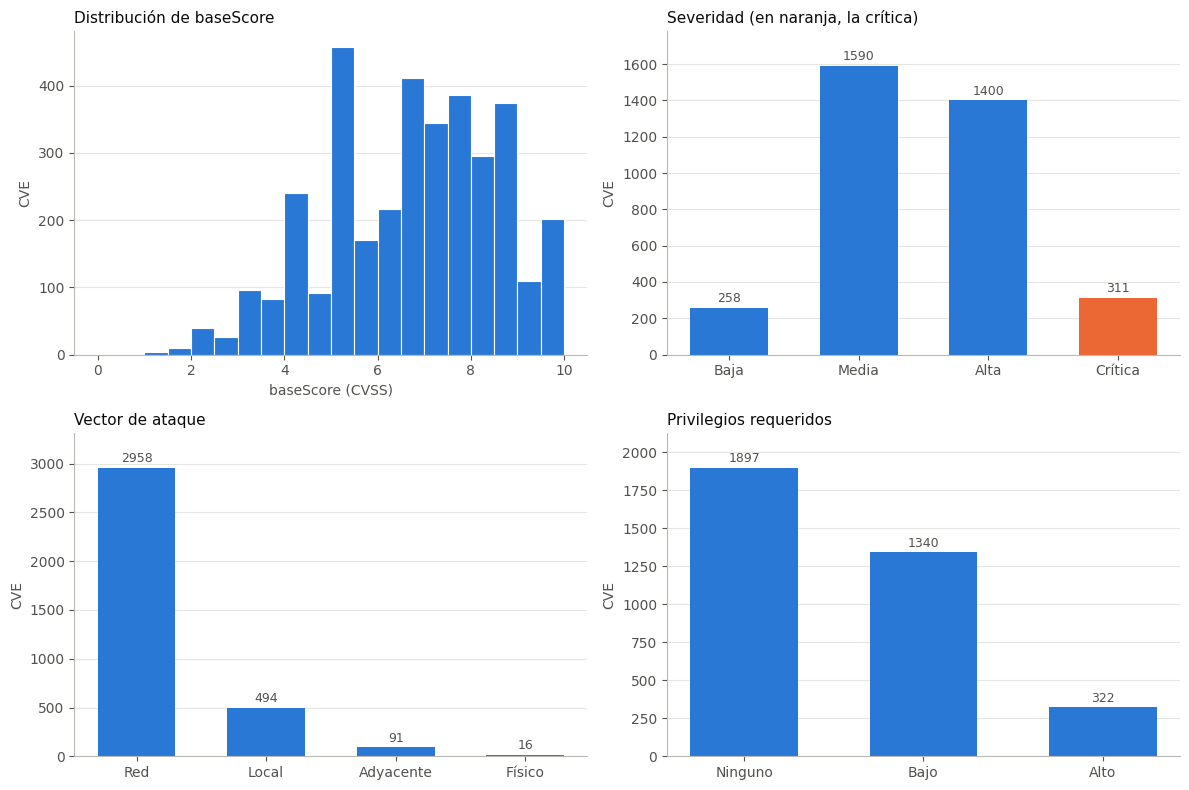

In [23]:
def barras(ax, serie, titulo, destacar=None):
    colores = [NARANJA if i == destacar else AZUL for i in serie.index]
    contenedor = ax.bar([str(i) for i in serie.index], serie.values, color=colores, width=0.6)
    ax.bar_label(contenedor, fmt="%d", padding=2, color=TEXTO2, fontsize=9)
    ax.set_ylim(top=serie.max() * 1.12)          # margen para que la etiqueta no toque el título
    estilo(ax, titulo, ylabel="CVE")

fig, ejes = plt.subplots(2, 2, figsize=(12, 8))

# (a) Histograma de baseScore
ax = ejes[0, 0]
ax.hist(dataset["baseScore"].dropna(), bins=np.arange(0, 10.5, 0.5), color=AZUL, edgecolor="white", linewidth=0.8)
estilo(ax, "Distribución de baseScore", "baseScore (CVSS)", "CVE")

# (b) Severidad
sev = dataset["severidad"].value_counts().reindex(ORDEN_SEVERIDAD).dropna()
sev.index = [ETIQ_SEVERIDAD[i] for i in sev.index]
barras(ejes[0, 1], sev, "Severidad (en naranja, la crítica)", destacar="Crítica")

# (c) Vector de ataque
vec = dataset["vector_ataque"].value_counts()
vec.index = [ETIQ_VECTOR[i] for i in vec.index]
barras(ejes[1, 0], vec, "Vector de ataque")

# (d) Privilegios requeridos
priv = dataset["privilegios"].value_counts().reindex(["N", "L", "H"]).dropna()   # orden natural: ninguno, bajo, alto
priv.index = [ETIQ_PRIVILEGIOS[i] for i in priv.index]
barras(ejes[1, 1], priv, "Privilegios requeridos")

fig.tight_layout()

### 6.5 Serie diaria
Dos gráficos separados, con el mismo eje de días: cuántos CVE se publicaron cada día y qué porcentaje de los puntuados fue crítico. Un día con publicaciones masivas pesa mucho en una sola semana.

,CVE,con_puntuacion,criticos,% críticos
fecha,,,,
2026-11-12,358,358,23,6.4
2026-11-13,792,792,42,5.3
2026-11-14,64,64,15,23.4
2026-11-15,112,112,15,13.4
2026-11-16,332,332,17,5.1
2026-11-17,1219,1219,103,8.4
2026-11-18,682,682,96,14.1


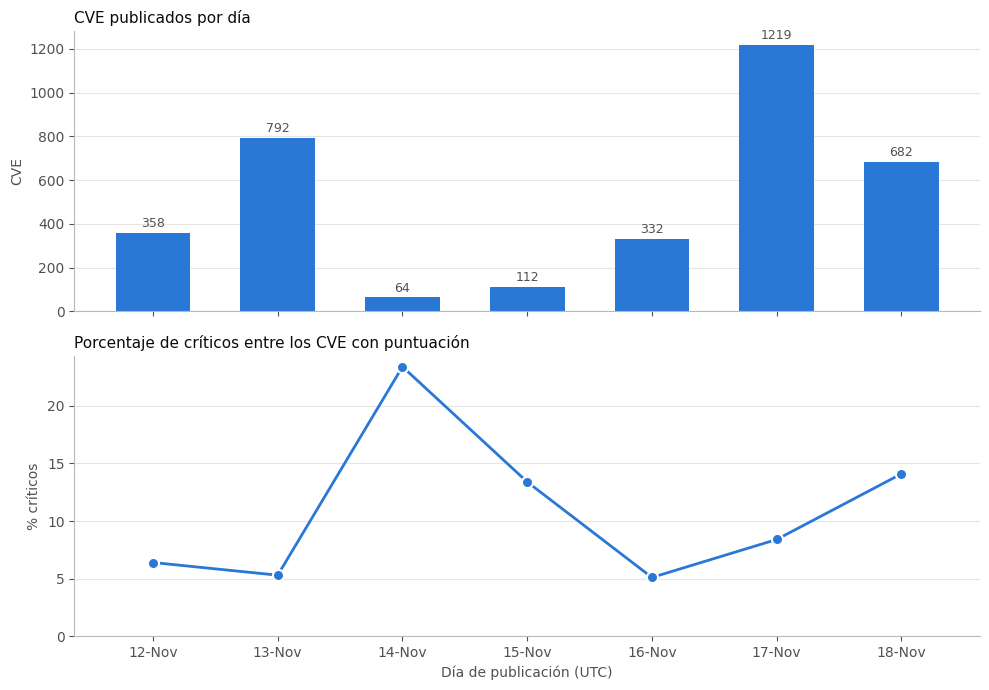

In [24]:
diario = dataset.groupby("fecha").agg(
    CVE=("id", "size"),
    con_puntuacion=("baseScore", "count"),
    criticos=("critico", "sum"),
)
diario["% críticos"] = (diario["criticos"] / diario["con_puntuacion"] * 100).round(1)
display(diario)

dias_txt = [pd.Timestamp(f).strftime("%d-%b") for f in diario.index]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

contenedor = ax1.bar(dias_txt, diario["CVE"], color=AZUL, width=0.6)
ax1.bar_label(contenedor, fmt="%d", padding=2, color=TEXTO2, fontsize=9)
estilo(ax1, "CVE publicados por día", ylabel="CVE")

ax2.plot(dias_txt, diario["% críticos"], color=AZUL, linewidth=2, marker="o", markersize=8,
         markerfacecolor=AZUL, markeredgecolor="white", markeredgewidth=1.5)
ax2.set_ylim(bottom=0)
estilo(ax2, "Porcentaje de críticos entre los CVE con puntuación", "Día de publicación (UTC)", "% críticos")

fig.tight_layout()

### 6.6 Debilidades (CWE) y fuentes
`cwe` y `fuente` quedan fuera de la fórmula del CVSS, así que aquí sí pueden aparecer hallazgos reales. En el ranking de CWE se omiten `NVD-CWE-Other` y `NVD-CWE-noinfo`, que no son debilidades concretas sino marcadores de «otra» o «sin información».

,CVE,pct_criticos
fuente,,
disclosure@vulncheck.com,908,7.4
secalert_us@oracle.com,578,8.5
security-advisories@github.com,320,10.6
chrome-cve-admin@google.com,195,9.2
audit@patchstack.com,165,4.2
security@wordfence.com,113,7.1
contact@wpscan.com,95,14.7
security_alert@emc.com,74,9.5
cna@vuldb.com,67,26.9


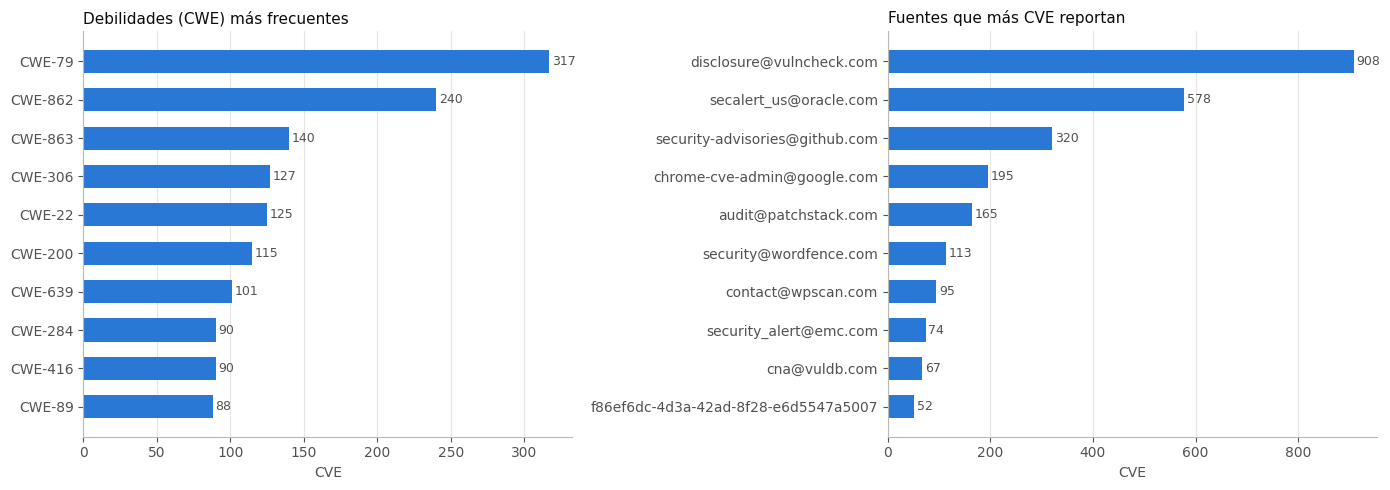

In [25]:
solo_cwe = dataset.loc[~dataset["cwe"].fillna("").str.startswith("NVD-CWE"), "cwe"]
cwe_top = solo_cwe.value_counts().head(10)
fuente_top = dataset["fuente"].value_counts().head(10)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for ax, serie, titulo in [(ax1, cwe_top, "Debilidades (CWE) más frecuentes"),
                          (ax2, fuente_top, "Fuentes que más CVE reportan")]:
    contenedor = ax.barh(serie.index[::-1], serie.values[::-1], color=AZUL, height=0.6)
    ax.bar_label(contenedor, fmt="%d", padding=2, color=TEXTO2, fontsize=9)
    estilo(ax, titulo, "CVE", rejilla="x")
fig.tight_layout()

# ¿Las fuentes que más reportan también concentran más críticos?
top_fuentes = dataset.loc[dataset["fuente"].isin(fuente_top.index)]
tabla_fuentes = top_fuentes.groupby("fuente").agg(
    CVE=("id", "size"),
    pct_criticos=("critico", lambda s: round(s.astype(float).mean() * 100, 1)),
).sort_values("CVE", ascending=False)
tabla_fuentes

### 6.7 Cruces entre variables
- **Severidad por vector de ataque:** muestra qué parte de cada severidad se explota por red, local, etc. (la relación es **por construcción** del CVSS).
- **Por estado de análisis:** `n_referencias` y la puntuación dependen de la etapa en que está el CVE (los *Received* suelen traer más referencias y menos análisis).

In [ ]:
cruce = pd.crosstab(dataset["severidad"], dataset["vector_ataque"], normalize="index").mul(100).round(1)
cruce = cruce.reindex([s for s in ORDEN_SEVERIDAD if s in cruce.index])
print("Severidad × vector de ataque (% por fila)")
display(cruce)

por_estado = dataset.groupby("estado").agg(
    CVE=("id", "size"),
    n_referencias_prom=("n_referencias", "mean"),
    baseScore_prom=("baseScore", "mean"),
).round(2)
print("\nPor estado de análisis")
display(por_estado)

### 6.8 Resumen de hallazgos
Se genera con los datos de la ejecución, para que el texto no quede desactualizado cuando cambie la ventana.

In [ ]:
p_critico = con_puntuacion["critico"].mean()
dia_max = diario["CVE"].idxmax()
red = (dataset["vector_ataque"] == "N").mean() * 100
sin_priv = (dataset["privilegios"] == "N").mean() * 100

print(f"• Periodo: {dataset['fecha'].min()} a {dataset['fecha'].max()} ({len(dataset)} CVE en el dataset).")
print(f"• baseScore: media {dataset['baseScore'].mean():.2f}, mediana {dataset['baseScore'].median():.1f}, "
      f"desviación {dataset['baseScore'].std():.2f}.")
print(f"• Críticos: {int(con_puntuacion['critico'].sum())} de {len(con_puntuacion)} con puntuación "
      f"(proporción {p_critico:.3f}).")
print(f"• El {red:.1f}% se explota por red y el {sin_priv:.1f}% no exige privilegios.")
print(f"• Día con más publicaciones: {dia_max} ({int(diario.loc[dia_max, 'CVE'])} CVE).")
if len(cwe_top):
    print(f"• Debilidad más frecuente: {cwe_top.index[0]} ({int(cwe_top.iloc[0])} CVE).")
print(f"• Fuente que más reporta: {fuente_top.index[0]} ({int(fuente_top.iloc[0])} CVE).")
print(f"• En el catálogo KEV: {int(dataset['kev'].sum())} CVE.")

## 7. Cierre del ciclo

| Etapa | Evidencia en el notebook |
|---|---|
| Consultar la API | Sección 1: ventana de 7 días, paginación, pausas y reintentos |
| Obtener la data | Sección 2: JSON crudo guardado en `nvd_crudo.json` |
| Armar el dataset | Sección 3: una fila por CVE con una sola puntuación CVSS |
| Limpiar | Sección 4: rechazados, duplicados, tipos, strings, nulos y cuadre de cuentas |
| Exportar a CSV | Sección 5: `cve_nvd_ultimos_7_dias.csv`, con diccionario de datos y verificación de lectura |
| Análisis descriptivo | Sección 6: resúmenes, frecuencias, gráficos y hallazgos |

**Para el software de Estadística:** el archivo de entrada es `cve_nvd_ultimos_7_dias.csv`. Las columnas que definen los eventos son `critico` (Bernoulli), `severidad`, `vector_ataque` y `privilegios`.

**Para repetir la corrida:** cada ejecución trae una ventana distinta y la NVD sigue actualizando CVE ya publicados. Si se necesita comparar resultados, hay que trabajar siempre con el mismo CSV.